# A abstenção replica entre modelos?

**Dissertação de mestrado (PPGCC/PUCRS).** Até aqui todo o estudo foi no **Llama-3.1-8B**.
Aqui replicamos o pipeline em **três modelos** para testar se o mecanismo de abstenção é
geral. Antes dos resultados, a §1 explica **como** medimos e **em que camada** — que é a
decisão metodológica central.

> **Conclusão (o resto do notebook detalha).**
> 1. **O mecanismo existe nos três modelos** — a abstenção é uma *direção* linear no
>    espaço interno, que separa "não sei" de "tenho veredito".
> 2. **A camada certa é model-específica** — cada modelo forma esse sinal numa
>    profundidade diferente (Llama no meio, Qwen3 mais fundo, DeepSeek fraco em toda parte).
> 3. **Intervir na direção controla a abstenção** — *suprimir* funciona nos três (o modelo
>    passa a decidir); *induzir* funciona bem em Llama e Qwen3.


> **Atualização (27/09/2026):** resultados com os SAEs **v1**. O v3 do Llama está pronto (`../02-sae-v3.ipynb`); DeepSeek e Qwen3 v3 estão em andamento.

## 0. Conceitos (glossário rápido)

- **Abstenção / NEI** — o modelo responde *"Not Enough Info"* em vez de dar um veredito
  (Supported/Refuted). É o comportamento que queremos localizar e controlar.
- **Direção de abstenção** — pegamos a ativação interna do modelo no **token da decisão**
  (o último token do prompt, logo antes de ele responder) e calculamos
  **média(casos NEI) − média(casos com veredito)**. Isso dá um **vetor** (uma "direção")
  no espaço interno do modelo.
- **AUC** — o quão bem essa direção separa NEI de decisivo: **0.5 = acaso**, **1.0 = perfeito**.
- **Camada** — a rede tem ~32–36 camadas empilhadas; medimos a ativação numa delas. *Qual*
  camada importa (§1).
- **β (no steering)** — intensidade da intervenção medida como **fração da norma do
  resíduo** da camada. β=1 soma uma perturbação do tamanho do próprio resíduo. Usamos β
  (e não uma magnitude crua) porque a escala interna varia MUITO entre modelos/camadas.


In [1]:
import json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def qwen_dir():
    return "v1_qwen3_l19" if os.path.exists("../../results/v1_qwen3_l19/abstention.json") else "v1_qwen3"
# (nome, pasta_resultados, cor)
MODELS = [("Llama-3.1-8B",   "v1_domain",   "#2a78d6"),
          ("DeepSeek-R1-8B", "v1_deepseek", "#eb6834"),
          ("Qwen3-8B",       qwen_dir(),    "#1baf7a")]
def load(p): return json.load(open(p, encoding="utf-8")) if os.path.exists(p) else {}

INK, GRID, SURF = "#0b0b0b", "#e6e5de", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "figure.dpi": 120, "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": .8, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold"})
print("Qwen3 usando:", qwen_dir())


Qwen3 usando: v1_qwen3_l19


## 1. Metodologia — em qual camada, e por quê?

A pergunta mais importante: **em que camada a abstenção vira uma direção legível?** Não
escolhemos por chute. Para **cada camada** de cada modelo, reconstruímos a direção de
abstenção num conjunto de treino e medimos o **AUC held-out** (separação NEI vs decisivo)
num conjunto de teste. O gráfico abaixo mostra essa varredura — é isso que justifica a
camada usada em todo o resto do estudo.


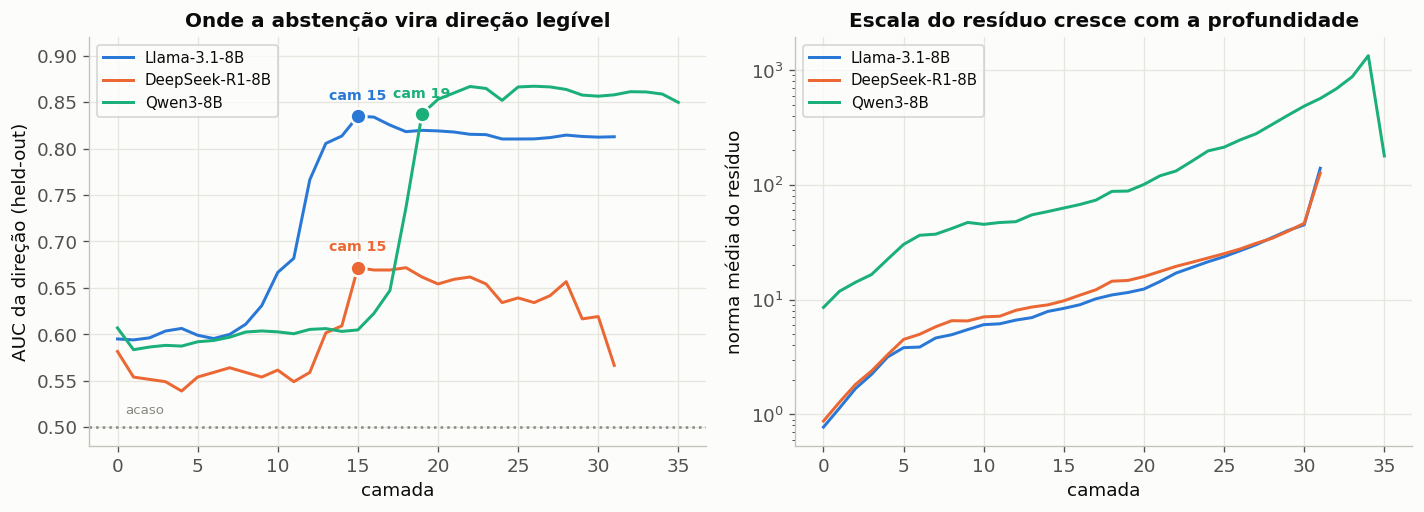

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for nm, d, c in MODELS:
    s = load(f"../../results/{d}/layer_sweep.json")
    if not s: continue
    L = s["layers"]; auc = s["auc_by_layer"]; used = s["layer_used"]
    ax[0].plot(L, auc, "-", color=c, lw=1.8, label=nm)
    ax[0].scatter([used], [auc[used]], s=90, color=c, edgecolor="white", zorder=5, lw=1.5)
    ax[0].annotate(f"cam {used}", (used, auc[used]), textcoords="offset points",
                   xytext=(0, 10), ha="center", fontsize=8.5, color=c, weight="bold")
    ax[1].plot(L, s["resid_norm_by_layer"], "-", color=c, lw=1.8, label=nm)
ax[0].axhline(0.5, ls=":", color="#898781"); ax[0].text(0.5, 0.515, "acaso", fontsize=8, color="#898781")
ax[0].set_xlabel("camada"); ax[0].set_ylabel("AUC da direção (held-out)")
ax[0].set_title("Onde a abstenção vira direção legível"); ax[0].set_ylim(0.48, 0.92); ax[0].legend(fontsize=9)
ax[1].set_xlabel("camada"); ax[1].set_ylabel("norma média do resíduo"); ax[1].set_yscale("log")
ax[1].set_title("Escala do resíduo cresce com a profundidade"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()


**Como ler.** *Esquerda:* eixo X = camada (0 = entrada, ~32–36 = saída), eixo Y =
AUC da direção de abstenção naquela camada (0.5 = acaso). O ponto grande marca a **camada
que usamos**. *Direita:* a norma média do resíduo por camada (escala log).

👉 **O que diz.** (1) A abstenção **não** é legível na entrada (AUC ~0.5–0.6) — ela
**emerge** conforme a rede processa. (2) **Cada modelo emerge numa profundidade
diferente:** o **Llama** atinge o pico no meio (~cam 15, AUC 0.84) e faz platô; o **Qwen3**
só dispara mais fundo (salta na cam 18–20, platô ~0.87 nas 22–26) — por isso a camada 15
o subestimava e migramos para a **camada 19**; o **DeepSeek** é fraco em *toda* a rede
(máx ~0.67), coerente com ser um modelo de raciocínio que decide *durante* o texto, não no
token da decisão. Usamos, em cada modelo, uma camada na sua região alta. (3) *Direita:* as
normas crescem ~100× com a profundidade e diferem por modelo (Qwen3 ~10× o Llama na camada
usada) — é por isso que o steering usa **β = fração do resíduo**, não uma magnitude fixa.


## 2. Discovery — o SAE de domínio localiza a abstenção?

Com a camada definida, treinamos um **SAE esparso (TopK)** ali e perguntamos: ele
**reconstrói** a decisão (erro baixo) e **condensa** a abstenção numa única feature
(cosseno alto entre a direção e a feature mais alinhada)?


In [3]:
rows = []
for nm, d, c in MODELS:
    m = load(f"../../checkpoints/{d}/metrics.json"); a = load(f"../../results/{d}/abstention.json")
    sw = load(f"../../results/{d}/layer_sweep.json")
    rows.append({"modelo": nm, "camada": sw.get("layer_used", "?"),
                 "AUC direção": round(a.get("auc_direction_heldout", np.nan), 3),
                 "FVU na decisão": round(a.get("fvu_decision_domainSAE", np.nan), 3),
                 "cos(direção, feature)": round(a.get("max_decoder_cos", np.nan), 3),
                 "features mortas": f"{100*m.get('dead_features',0)/32768:.0f}%"})
pd.DataFrame(rows).set_index("modelo")


,camada,AUC direção,FVU na decisão,"cos(direção, feature)",features mortas
modelo,,,,,
Llama-3.1-8B,15,0.839,0.294,0.673,33%
DeepSeek-R1-8B,15,0.795,0.400,0.454,22%
Qwen3-8B,19,0.833,0.474,0.417,33%


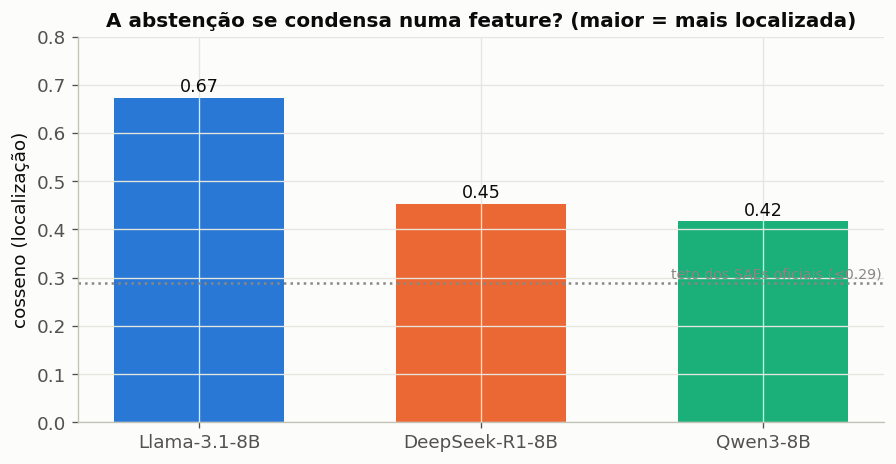

In [4]:
fig, ax = plt.subplots(figsize=(7.6, 4))
names = [m[0] for m in MODELS]; cors = [m[2] for m in MODELS]
cos = [load(f"../../results/{m[1]}/abstention.json").get("max_decoder_cos", np.nan) for m in MODELS]
b = ax.bar(names, cos, color=cors, width=.6)
ax.axhline(0.29, ls=":", color="#898781")
ax.text(2.42, 0.30, "teto dos SAEs oficiais (≤0.29)", fontsize=8.5, color="#898781", ha="right")
ax.set_ylim(0, 0.8); ax.set_ylabel("cosseno (localização)")
ax.set_title("A abstenção se condensa numa feature? (maior = mais localizada)")
for r, v in zip(b, cos): ax.text(r.get_x()+r.get_width()/2, v+.012, f"{v:.2f}", ha="center", fontsize=10.5)
plt.tight_layout(); plt.show()


**Como ler.** Cada barra é um modelo; eixo Y = cosseno entre a direção de abstenção
e a feature mais alinhada do SAE (0 = distribuída em muitas features, 1 = é *uma* feature).
A linha pontilhada é o teto dos SAEs oficiais que queríamos superar.

👉 **O que diz.** Nos três, o SAE de domínio **supera o teto oficial** e reconstrói bem a
decisão (FVU 0.29–0.47 na tabela, ante ~8–20 dos oficiais). O **Llama** condensa a
abstenção quase numa única feature (0.67); **DeepSeek** e **Qwen3** localizam menos
(~0.42–0.45) — nesses a abstenção está mais *distribuída*, e a **direção** (não uma feature
isolada) é o objeto confiável, como veremos na generalização.


## 3. Generalização — a direção vale fora do domínio de treino?

O SAE foi treinado só em VitaminC+FEVER. Testamos a **direção** de abstenção em **4
datasets nunca vistos** (web, clima, ciência, saúde), sem re-treino.


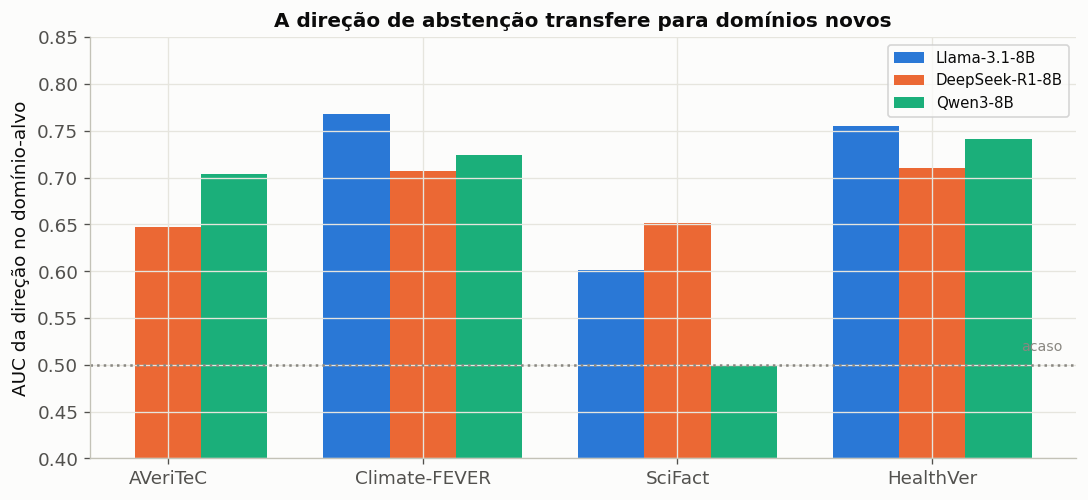

In [5]:
DOMS = [("AVeriTeC","averitec"), ("Climate-FEVER","climate_fever"),
        ("SciFact","scifact"), ("HealthVer","healthver")]
fig, ax = plt.subplots(figsize=(9.2, 4.3))
x = np.arange(len(DOMS)); w = 0.26
for j, (nm, d, c) in enumerate(MODELS):
    ys = [load(f"../../results/{d}/generalize_{k}.json").get("auc_dir", np.nan) for _, k in DOMS]
    bars = ax.bar(x + (j-1)*w, ys, w, color=c, label=nm)
ax.axhline(0.5, ls=":", color="#898781"); ax.text(3.35, 0.515, "acaso", fontsize=8.5, color="#898781")
ax.set_xticks(x); ax.set_xticklabels([d[0] for d in DOMS]); ax.set_ylim(0.4, 0.85)
ax.set_ylabel("AUC da direção no domínio-alvo")
ax.set_title("A direção de abstenção transfere para domínios novos"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


**Como ler.** Eixo X = os 4 datasets-alvo; três barras por dataset (uma por modelo).
Eixo Y = AUC usando a **direção** de abstenção (0.5 = acaso). Usamos a direção porque é o
objeto robusto — onde o SAE localiza forte (Llama), a feature isolada também transfere.

👉 **O que diz.** Nos **três modelos** a direção transfere **acima do acaso** para os
quatro domínios (Llama 0.60–0.78, DeepSeek 0.65–0.71, Qwen3 0.50–0.74). SciFact é o mais
difícil. Ou seja, a abstenção aprendida em VitaminC/FEVER é um mecanismo **geral do
modelo**, não um decorar de domínio.


## 4. Steering — intervir na direção controla a abstenção?

Teste **causal**: durante a geração, na camada usada, **somamos** (β>0, induzir) ou
**subtraímos** (β<0, suprimir) a direção de abstenção, e medimos quanto o veredito muda.
β é a fração da norma do resíduo (comparável entre modelos).


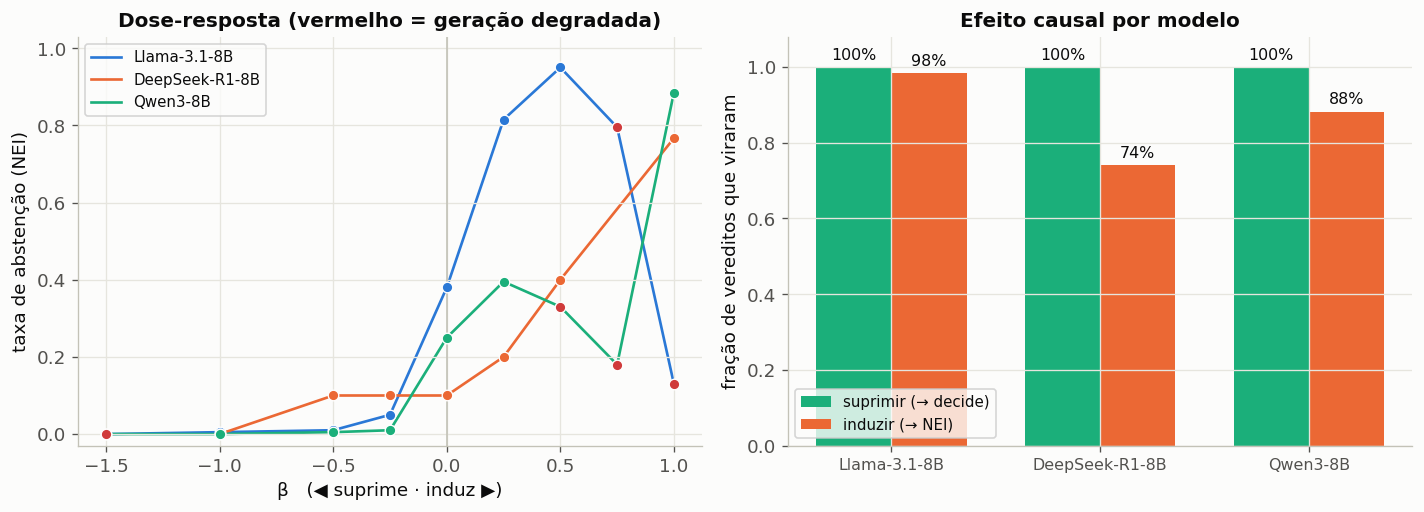

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
sup, ind = [], []
for nm, d, c in MODELS:
    s = load(f"../../results/{d}/steering_beta.json")
    if not s: sup.append(np.nan); ind.append(np.nan); continue
    betas = sorted(float(b) for b in s["nei_rate"])
    nei = [s["nei_rate"][str(b)] for b in betas]
    unread = [s["unreadable_rate"][str(b)] for b in betas]
    ax[0].plot(betas, nei, "-", color=c, lw=1.6, zorder=1, label=nm)
    for b, y, u in zip(betas, nei, unread):
        ax[0].scatter([b], [y], s=40, zorder=3, edgecolor="white", lw=.8,
                      color=(c if u < 0.2 else "#d03b3b"))
    sup.append(s.get("suppressed_abstention", np.nan)); ind.append(s.get("induced_abstention", np.nan))
ax[0].axvline(0, color="#c3c2b7", lw=1)
ax[0].set_xlabel("β   (◀ suprime · induz ▶)"); ax[0].set_ylabel("taxa de abstenção (NEI)")
ax[0].set_title("Dose-resposta (vermelho = geração degradada)"); ax[0].set_ylim(-.03, 1.03); ax[0].legend(fontsize=9)
names = [m[0] for m in MODELS]; xx = np.arange(len(names)); ww = 0.36
b1 = ax[1].bar(xx - ww/2, sup, ww, color="#1baf7a", label="suprimir (→ decide)")
b2 = ax[1].bar(xx + ww/2, ind, ww, color="#eb6834", label="induzir (→ NEI)")
ax[1].set_xticks(xx); ax[1].set_xticklabels(names, fontsize=9.5); ax[1].set_ylim(0, 1.08)
ax[1].set_ylabel("fração de vereditos que viraram"); ax[1].set_title("Efeito causal por modelo"); ax[1].legend(fontsize=9)
for bars in (b1, b2):
    for r in bars:
        h = r.get_height()
        if h == h: ax[1].text(r.get_x()+r.get_width()/2, h+.02, f"{h:.0%}", ha="center", fontsize=9.5)
plt.tight_layout(); plt.show()


**Como ler.** *Esquerda:* uma curva por modelo; eixo X = β (negativo suprime,
positivo induz), eixo Y = taxa de NEI. Pontos **vermelhos** = a geração degradou (β
grande demais quebra o texto — esperado; não conta como efeito válido). *Direita:* quanto
os vereditos viraram — **verde** = suprimir (base NEI → decisivo), **laranja** = induzir
(base decisivo → NEI).

👉 **O que diz.** **Suprimir a abstenção funciona nos três modelos** (~100%: some a
direção e o modelo passa a decidir). **Induzir** é forte no **Llama (98%)** e **Qwen3
(88%)**, e moderado no **DeepSeek (74%)**. *Nota:* um teste inicial do DeepSeek com
perturbação pequena deu "plano" — ao igualar a força em β, ele responde; o efeito só
estava subdimensionado.


## 5. Discussão

**O mecanismo é geral.** Nos três modelos a abstenção é uma **direção linear** que emerge
na rede, é reconstruída por um SAE de domínio, **transfere** para 4 domínios novos e
**controla causalmente** o veredito quando intervimos. Isso sustenta que abstenção
("não sei") é um mecanismo **compartilhado**, não um artefato de um modelo.

**A camada é a decisão metodológica central.** A varredura (§1) mostra *onde* medir: o
sinal emerge em profundidades diferentes por modelo. Fixar a camada 15 para todos era
injusto com o Qwen3 (sinal fundo); usar a camada boa de cada um (Llama 15, DeepSeek 15,
Qwen3 19) dá a comparação justa. Para o Qwen3 o pico exato é ~26; a 19 já está na região
forte (0.84) — um ajuste fino possível.

**Instruct vs reasoning.** O DeepSeek (reasoning) tem o sinal mais fraco *no token da
decisão* (máx AUC 0.67), porque decide *durante* o raciocínio — ainda assim a direção
controla o veredito quando a intervenção tem força. Foi preciso medir em β (fração do
resíduo) para comparar de forma justa; as normas internas variam ~10× entre modelos.

**Limitações.** Um SAE por modelo; features mortas ainda altas (22–33%); steering do
DeepSeek com amostra menor (custo do raciocínio); Qwen3 na camada 19 (não no pico 26).

**Próximos passos.** Reduzir features mortas; publicar os SAEs (Hugging Face + Neuronpedia);
e escrever o texto da dissertação/paper — a tese de uma *feature de abstenção* que vale
entre datasets **e** entre modelos.


## Referências

- **Arditi, A., et al. (2024).** Refusal in Language Models Is Mediated by a Single Direction. *arXiv:2406.11717.*
- **Gao, L., et al. (2024).** Scaling and Evaluating Sparse Autoencoders (TopK). *arXiv:2406.04093.*
- **Marks, S., & Tegmark, M. (2023).** The Geometry of Truth (diferença de médias). *arXiv:2310.06824.*
- **Turner, A., et al. (2023).** Activation Addition. *arXiv:2308.10248.*
- **Schuster, T., et al. (2021).** VitaminC. *NAACL 2021.* · **Thorne, J., et al. (2018).** FEVER. *NAACL 2018.*
